# Potencial de valorización catastral por manzana

## Informe exploratorio, resultados y análisis

**Corte:** avalúos de referencia 2026 · **Horizonte analizado:** 2026–2029 · **Unidad:** manzana catastral.

Este informe documenta el EDA inicial, la construcción del objetivo, la validación temporal y la lectura del ranking experimental. El análisis complementa los notebooks y resultados previos del proyecto; no los reemplaza ni modifica.

> **Alcance:** se estima qué manzanas se parecen a las que históricamente tuvieron un crecimiento catastral alto frente a manzanas de precio inicial comparable. El puntaje ordena oportunidades relativas; no pronostica un precio futuro en pesos ni una rentabilidad de mercado.

El notebook carga las fuentes existentes desde `../data` y los resultados generados en `outputs/`. Ejecútelo con el kernel `geoenv` desde esta carpeta o desde la raíz del proyecto.

In [1]:
from pathlib import Path
import json
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "font.size": 10,
    "figure.dpi": 120,
})

here = Path.cwd().resolve()
ROOT = next((p for p in (here, *here.parents)
             if (p / "data" / "raw" / "valor_referencia_serie.csv.gz").exists()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto con data/raw/valor_referencia_serie.csv.gz")
PACKAGE = ROOT / "potencial_manzanas"
OUTPUTS = PACKAGE / "outputs"

manzanas = gpd.read_file(ROOT / "data" / "processed" / "manzanas.gpkg")
serie = pd.read_csv(ROOT / "data" / "raw" / "valor_referencia_serie.csv.gz",
                    dtype={"MANCODIGO": str})
entrenamiento = pd.read_csv(OUTPUTS / "entrenamiento_historico.csv.gz",
                            dtype={"MANCODIGO": str})
metricas = pd.read_csv(OUTPUTS / "backtest_metricas.csv")
resumen_modelos = pd.read_csv(OUTPUTS / "backtest_resumen.csv")
predicciones_oof = pd.read_csv(OUTPUTS / "backtest_predicciones.csv.gz",
                               dtype={"MANCODIGO": str})
ranking = pd.read_csv(OUTPUTS / "potencial_2026_2029.csv.gz",
                      dtype={"MANCODIGO": str})
contexto = pd.read_csv(OUTPUTS / "contexto_edificaciones_2026.csv.gz",
                       dtype={"MANCODIGO": str})
importancia = pd.read_csv(OUTPUTS / "importancia_variables.csv")
with open(OUTPUTS / "informe_ejecucion.json", encoding="utf-8") as f:
    config = json.load(f)

for frame in (manzanas, serie, entrenamiento, predicciones_oof, ranking, contexto):
    if "MANCODIGO" in frame.columns:
        frame["MANCODIGO"] = frame["MANCODIGO"].astype(str).str.zfill(9)
serie["ANO"] = pd.to_numeric(serie["ANO"], errors="coerce").astype("Int64")
serie["V_REF"] = pd.to_numeric(serie["V_REF"], errors="coerce")
manzanas["sector"] = manzanas["MANCODIGO"].str[:6]
ranking["sector"] = ranking["MANCODIGO"].str[:6]
contexto["sector"] = contexto["MANCODIGO"].str[:6]

print(f"Raíz del proyecto: {ROOT}")
print(f"Manzanas procesadas: {len(manzanas):,} · Avalúos observados: {len(serie):,} · Ejemplos históricos: {len(entrenamiento):,}")
print(f"Ranking: {len(ranking):,} manzanas · período objetivo: {config['anio_corte']}–{config['anio_fin_objetivo']}")

Raíz del proyecto: C:\Users\Usuario\Proyectos\Catastro_project
Manzanas procesadas: 41,570 · Avalúos observados: 427,839 · Ejemplos históricos: 249,442
Ranking: 41,823 manzanas · período objetivo: 2026–2029


## 1. Resumen ejecutivo

El conjunto procesado reúne geometría, avalúo de referencia por m², características espaciales y una fotografía actual de la morfología edificatoria. La serie catastral contiene observaciones anuales de 2017 a 2026. Se construyó un clasificador supervisado que identifica el 20 % superior de crecimiento catastral ajustado por precio inicial y se evaluó con cortes temporales fuera de muestra.

La morfología de edificios se informa en un indicador contextual separado. Solo existe la fotografía actual de esas características, por lo que incorporarla al entrenamiento histórico daría al modelo información que no estaba disponible en los años evaluados.

In [2]:
modelo_elegido = config["mejor_modelo_por_promedio_precision"]
metricas_modelo = resumen_modelos.set_index("modelo")
ultimo_origen = int(config["origen_validacion_mas_reciente"])
ultimo = metricas[(metricas.modelo == modelo_elegido) & (metricas.origen_validacion == ultimo_origen)].iloc[0]
base_ultimo = metricas[(metricas.modelo == "linea_base_sin_senal") & (metricas.origen_validacion == ultimo_origen)].iloc[0]
ci = config["lift_oof_sector_bootstrap"]
fila_modelo = metricas_modelo.loc[modelo_elegido]
indicadores = pd.DataFrame([
    ("Manzanas con avalúo 2026", f"{len(ranking):,}"),
    ("Modelo seleccionado", modelo_elegido),
    ("Average precision promedio en 4 validaciones", f"{fila_modelo.promedio_precision:.3f}"),
    (f"Precisión del top 20 % en origen {ultimo_origen}", f"{ultimo.precision_top_fraccion:.1%} (base: {base_ultimo.precision_top_fraccion:.1%})"),
    ("Lift agregado fuera de tiempo (IC sectorial 95 %)", f"{ci['lift_media']:.2f}× ({ci['lift_ic95_inferior']:.2f}–{ci['lift_ic95_superior']:.2f})"),
    ("Candidatas contextuales: valor alto / intensidad baja", f"{int(contexto.valor_alto_baja_intensidad.sum()):,}"),
], columns=["Indicador", "Resultado"])
display(indicadores)

,Indicador,Resultado
0,Manzanas con avalúo 2026,"41,823"
1,Modelo seleccionado,hist_gradient
2,Average precision promedio en 4 validaciones,0.338
3,Precisión del top 20 % en origen 2023,29.6% (base: 20.0%)
4,Lift agregado fuera de tiempo (IC sectorial 95 %),1.74× (1.64–1.85)
5,Candidatas contextuales: valor alto / intensid...,"1,389"


## 2. Fuentes y unidad de análisis

| Fuente | Contenido usado | Nivel / periodo |
|---|---|---|
| `data/raw/valor_referencia_serie.csv.gz` | Avalúo de referencia (`V_REF`) y código de manzana | Manzana, 2017–2026 |
| `data/processed/manzanas.gpkg` | Avalúo 2026, uso, estrato, morfología agregada, ubicación y distancias | Una fila por manzana |
| `outputs/entrenamiento_historico.csv.gz` | Variables conocidas al origen y etiqueta histórica | Manzana × ventana temporal |
| `outputs/backtest_*.csv*` | Predicciones fuera de tiempo y métricas | Manzana × origen × modelo |
| `outputs/potencial_2026_2029.csv.gz` | Puntaje relativo y puesto en el ranking futuro | Manzana, corte 2026 |
| `outputs/contexto_edificaciones_2026.csv.gz` | Precio relativo e intensidad edificatoria actual | Manzana, fotografía actual |

La unidad se mantiene como **manzana** porque el avalúo en serie y las características agregadas están disponibles a ese nivel. El proyecto no identifica directamente predios con capacidad legal de desarrollo.

In [3]:
resumen_fuentes = pd.DataFrame([
    {"Tabla": "manzanas.gpkg", "Filas": len(manzanas), "Columnas": len(manzanas.columns), "Códigos únicos": manzanas.MANCODIGO.nunique()},
    {"Tabla": "serie de avalúos", "Filas": len(serie), "Columnas": len(serie.columns), "Códigos únicos": serie.MANCODIGO.nunique()},
    {"Tabla": "entrenamiento histórico", "Filas": len(entrenamiento), "Columnas": len(entrenamiento.columns), "Códigos únicos": entrenamiento.MANCODIGO.nunique()},
    {"Tabla": "ranking 2026–2029", "Filas": len(ranking), "Columnas": len(ranking.columns), "Códigos únicos": ranking.MANCODIGO.nunique()},
    {"Tabla": "contexto edificatorio", "Filas": len(contexto), "Columnas": len(contexto.columns), "Códigos únicos": contexto.MANCODIGO.nunique()},
])
display(resumen_fuentes)
display(pd.DataFrame({
    "Año": sorted(serie.ANO.dropna().astype(int).unique()),
    "Registros con avalúo": [serie.loc[serie.ANO == y, "MANCODIGO"].nunique() for y in sorted(serie.ANO.dropna().astype(int).unique())],
}))

,Tabla,Filas,Columnas,Códigos únicos
0,manzanas.gpkg,41570,39,41570
1,serie de avalúos,427839,4,44276
2,entrenamiento histórico,249442,35,43259
3,ranking 2026–2029,41823,15,41823
4,contexto edificatorio,41570,25,41570


,Año,Registros con avalúo
0,2017,43899
1,2018,43899
2,2019,43845
3,2020,42771
4,2021,43958
5,2022,41583
6,2023,42093
7,2024,42031
8,2025,41864
9,2026,41823


## 3. EDA inicial y calidad de datos

Primero se revisan duplicados, cobertura anual, valores faltantes y cambios de avalúo sin modificación entre años consecutivos. La mediana representa mejor el nivel típico que el promedio cuando existe una distribución de precios sesgada.

In [4]:
duplicados_manzana = int(manzanas.MANCODIGO.duplicated().sum())
duplicados_serie = int(serie.duplicated(["MANCODIGO", "ANO"]).sum())
serie_valida = serie.dropna(subset=["MANCODIGO", "ANO", "V_REF"]).query("V_REF > 0").copy()
panel = serie_valida.pivot_table(index="MANCODIGO", columns="ANO", values="V_REF", aggfunc="median").sort_index(axis=1)
anios = [int(a) for a in panel.columns]
calidad = []
for year in anios:
    values = panel[year]
    calidad.append({
        "Año": year,
        "Manzanas con avalúo": int(values.notna().sum()),
        "Mediana COP/m²": values.median(),
        "P25 COP/m²": values.quantile(.25),
        "P75 COP/m²": values.quantile(.75),
    })
calidad_anual = pd.DataFrame(calidad)

congelamiento = []
for year in anios[1:]:
    prev, curr = panel[year - 1], panel[year]
    ambas = prev.notna() & curr.notna()
    congelamiento.append({
        "Transición": f"{year-1}→{year}",
        "Manzanas comparables": int(ambas.sum()),
        "Sin cambio": float(np.isclose(prev[ambas], curr[ambas], rtol=0, atol=1e-12).mean()) if ambas.any() else np.nan,
    })
congelamiento = pd.DataFrame(congelamiento)

print(f"IDs duplicados en manzanas: {duplicados_manzana:,}; pares manzana-año duplicados en serie: {duplicados_serie:,}")
print("Los pares repetidos se resumen con la mediana al construir la serie manzana-año.")
print(f"Registros con V_REF no positiva o campos básicos faltantes: {len(serie) - len(serie_valida):,}")
display(calidad_anual.style.format({"Mediana COP/m²": "{:,.0f}", "P25 COP/m²": "{:,.0f}", "P75 COP/m²": "{:,.0f}"}))
display(congelamiento.style.format({"Sin cambio": "{:.1%}"}))

campos_eda = [c for c in ["cop_m2", "estrato", "ivs", "n_construcciones", "n_lotes", "area_construida_m2", "indice_construccion", "indice_ocupacion", "pisos_prom_pond"] if c in manzanas]
faltantes = (manzanas[campos_eda].isna().mean().sort_values(ascending=False)
             .rename("Fracción faltante").to_frame())
display(faltantes.style.format({"Fracción faltante": "{:.1%}"}))

IDs duplicados en manzanas: 0; pares manzana-año duplicados en serie: 73
Los pares repetidos se resumen con la mediana al construir la serie manzana-año.
Registros con V_REF no positiva o campos básicos faltantes: 5,876


,Año,Manzanas con avalúo,Mediana COP/m²,P25 COP/m²,P75 COP/m²
0,2017,42643,"1,200,000","600,000","1,800,000"
1,2018,42767,"1,400,000","690,000","2,000,000"
2,2019,42734,"1,500,000","760,000","2,200,000"
3,2020,42771,"1,700,000","850,000","2,400,000"
4,2021,41587,"1,900,000","1,100,000","2,650,000"
5,2022,41583,"1,900,000","1,100,000","2,650,000"
6,2023,42093,"2,050,000","1,100,000","2,800,000"
7,2024,42031,"2,150,000","1,160,000","2,970,000"
8,2025,41864,"2,360,000","1,280,000","3,200,000"
9,2026,41823,"2,590,000","1,490,000","3,500,000"


,Transición,Manzanas comparables,Sin cambio
0,2017→2018,42638,6.3%
1,2018→2019,42662,10.6%
2,2019→2020,42653,5.6%
3,2020→2021,41512,4.2%
4,2021→2022,41583,100.0%
5,2022→2023,41427,10.4%
6,2023→2024,41933,8.8%
7,2024→2025,41738,2.9%
8,2025→2026,41608,3.9%


,Fracción faltante
estrato,10.2%
ivs,8.8%
area_construida_m2,5.3%
n_construcciones,5.3%
n_lotes,5.3%
indice_ocupacion,5.3%
indice_construccion,5.3%
pisos_prom_pond,5.3%
cop_m2,0.0%


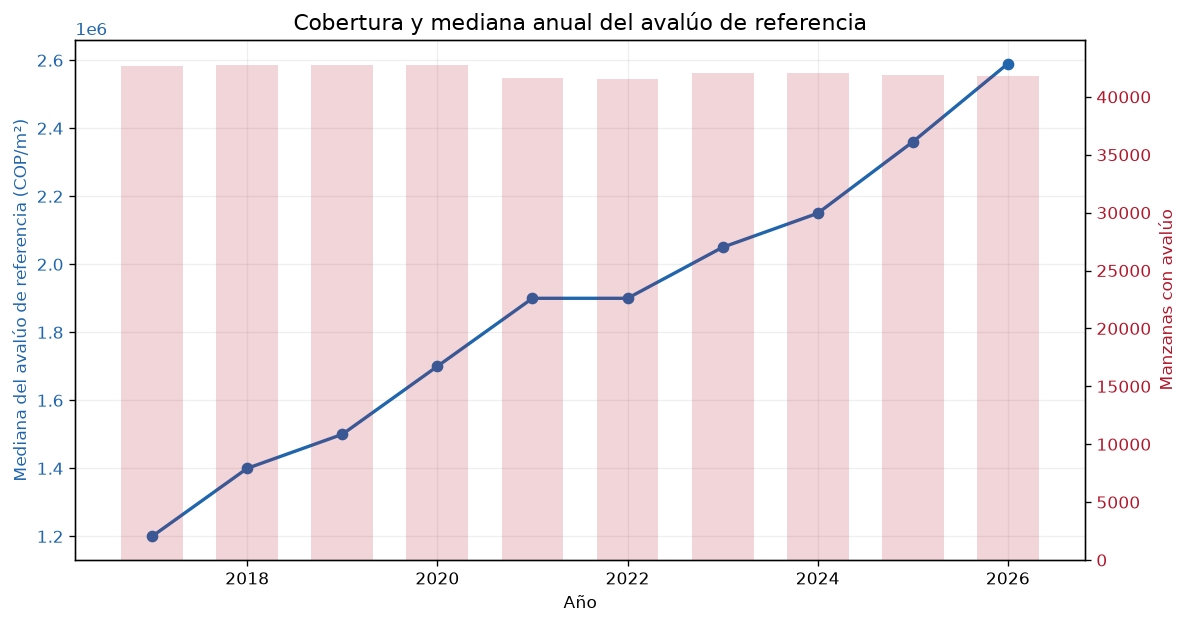

La mediana nominal pasa de **$1,200,000 COP/m² en 2017** a **$2,590,000 COP/m² en 2026** (115.8 % acumulado). Esta variación no está deflactada y no debe leerse como valorización real ni rendimiento de inversión.

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 5.3))
ax1.plot(calidad_anual["Año"], calidad_anual["Mediana COP/m²"], marker="o", color="#2166ac", linewidth=2)
ax1.set_ylabel("Mediana del avalúo de referencia (COP/m²)", color="#2166ac")
ax1.tick_params(axis="y", labelcolor="#2166ac")
ax1.set_xlabel("Año")
ax1.grid(alpha=.2)
ax2 = ax1.twinx()
ax2.bar(calidad_anual["Año"], calidad_anual["Manzanas con avalúo"], alpha=.18, color="#b2182b", width=.65)
ax2.set_ylabel("Manzanas con avalúo", color="#b2182b")
ax2.tick_params(axis="y", labelcolor="#b2182b")
ax1.set_title("Cobertura y mediana anual del avalúo de referencia")
fig.tight_layout()
plt.show()

if len(calidad_anual) > 1:
    first, last = calidad_anual.iloc[0], calidad_anual.iloc[-1]
    pct_nominal = (last["Mediana COP/m²"] / first["Mediana COP/m²"] - 1) * 100
    display(Markdown(
        f"La mediana nominal pasa de **${first['Mediana COP/m²']:,.0f} COP/m² en {int(first['Año'])}** "
        f"a **${last['Mediana COP/m²']:,.0f} COP/m² en {int(last['Año'])}** ({pct_nominal:.1f} % acumulado). "
        "Esta variación no está deflactada y no debe leerse como valorización real ni rendimiento de inversión."
    ))

### Distribución del avalúo 2026

El avalúo de referencia es asimétrico: se muestra en escala logarítmica para permitir la comparación entre rangos amplios. Las categorías de uso se limitan a las más frecuentes para que la gráfica sea legible.

,Uso,manzanas,mediana_cop_m2
0,RESIDENCIAL,35516,"2,670,000"
1,OTROS,2454,"569,426"
2,COMERCIO Y OFICINAS,1632,"4,200,000"
3,DOTACIONAL,781,"1,545,063"
4,BODEGAS,741,"3,300,000"
5,DEPOSITOS Y PARQUEADEROS,300,"3,478,000"
6,INDUSTRIAL,146,"3,326,000"


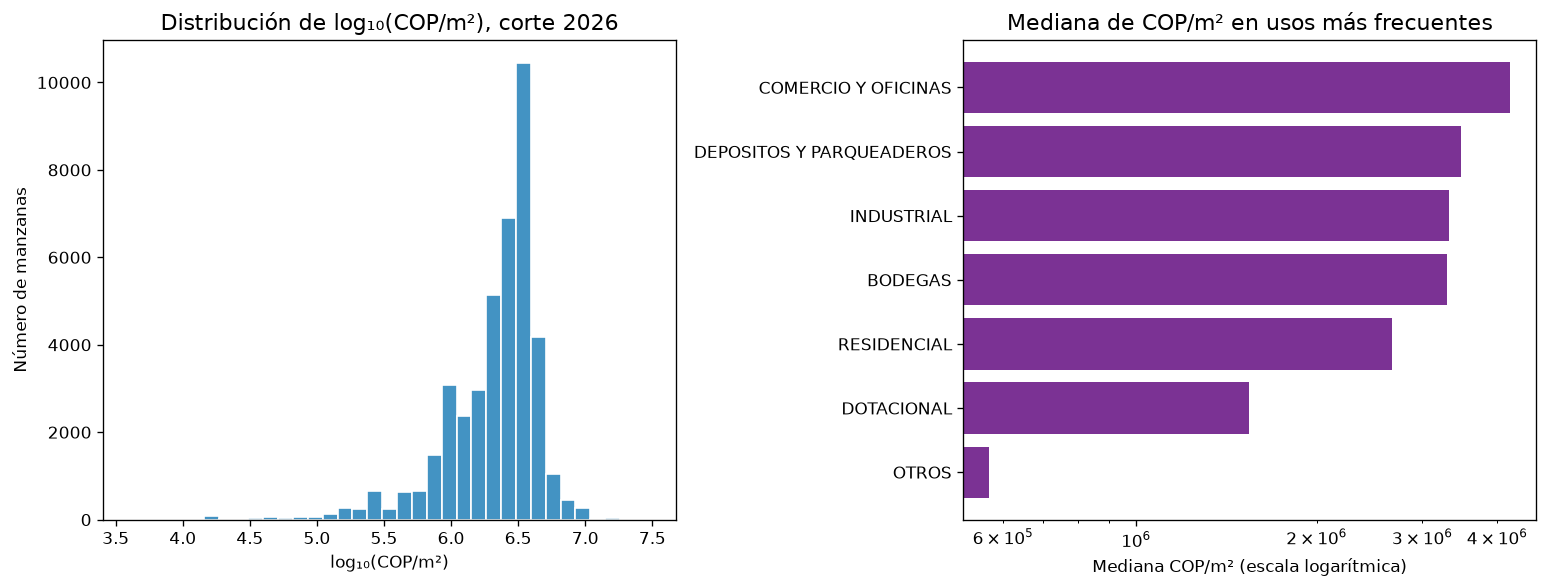

,manzanas,mediana_cop_m2
estrato,,
1.000000,6084,"940,000"
2.000000,15137,"2,250,000"
3.000000,11853,"3,489,000"
4.000000,2391,"3,860,000"
5.000000,1011,"4,000,000"
6.000000,855,"5,750,000"
nan,4239,"960,000"


In [6]:
actual = manzanas.copy()
actual["cop_m2"] = pd.to_numeric(actual["cop_m2"], errors="coerce")
valores_2026 = actual.loc[actual.cop_m2 > 0, "cop_m2"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(np.log10(valores_2026), bins=35, color="#4393c3", edgecolor="white")
axes[0].set_title("Distribución de log₁₀(COP/m²), corte 2026")
axes[0].set_xlabel("log₁₀(COP/m²)")
axes[0].set_ylabel("Número de manzanas")

if "uso" in actual:
    uso = (actual.dropna(subset=["cop_m2", "uso"])
           .groupby("uso", observed=True).agg(
               manzanas=("MANCODIGO", "nunique"), mediana_cop_m2=("cop_m2", "median"))
           .sort_values("manzanas", ascending=False))
    top_uso = uso.head(9).sort_values("mediana_cop_m2")
    axes[1].barh(top_uso.index.astype(str), top_uso.mediana_cop_m2, color="#7b3294")
    axes[1].set_xscale("log")
    axes[1].set_title("Mediana de COP/m² en usos más frecuentes")
    axes[1].set_xlabel("Mediana COP/m² (escala logarítmica)")
    display(uso.head(12).reset_index().rename(columns={"uso": "Uso"}).style.format({"mediana_cop_m2": "{:,.0f}"}))
else:
    axes[1].axis("off")
fig.tight_layout()
plt.show()

if "estrato" in actual:
    display(actual.groupby("estrato", dropna=False).agg(
        manzanas=("MANCODIGO", "nunique"), mediana_cop_m2=("cop_m2", "median")
    ).sort_index().style.format({"mediana_cop_m2": "{:,.0f}"}))

### Avalúo y morfología actual

La relación entre precio e intensidad ayuda a describir el contexto urbano. No identifica por sí sola potencial normativo: para determinar edificabilidad se necesitarían, entre otros insumos, el lote predial y las reglas de uso y aprovechamiento aplicables del POT.

,Variable,No nulos,Mediana,P75
0,indice_construccion,39378,1.957629,2.516877
1,indice_ocupacion,39378,0.874559,0.990863
2,pisos_prom_pond,39378,2.309000,2.763000
3,n_construcciones,39378,53.000000,79.000000
4,n_lotes,39378,20.000000,29.000000


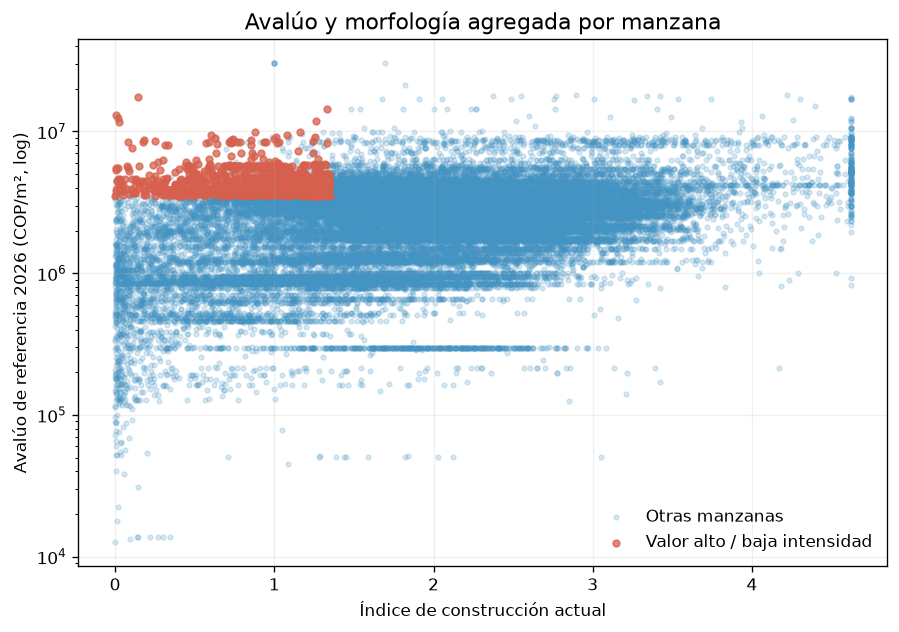

In [7]:
morfo_cols = [c for c in ["indice_construccion", "indice_ocupacion", "pisos_prom_pond", "n_construcciones", "n_lotes"] if c in actual]
display(pd.DataFrame({
    "Variable": morfo_cols,
    "No nulos": [int(actual[c].notna().sum()) for c in morfo_cols],
    "Mediana": [actual[c].median() for c in morfo_cols],
    "P75": [actual[c].quantile(.75) for c in morfo_cols],
}))

morfo = actual.dropna(subset=["cop_m2", "indice_construccion"]).copy()
flags = contexto[["MANCODIGO", "valor_alto_baja_intensidad", "valor_m2_percentil", "intensidad_edificatoria_percentil"]]
morfo = morfo.merge(flags, on="MANCODIGO", how="left")
fig, ax = plt.subplots(figsize=(8.7, 5.7))
comunes = morfo[~morfo.valor_alto_baja_intensidad.fillna(False)]
destacadas = morfo[morfo.valor_alto_baja_intensidad.fillna(False)]
ax.scatter(comunes.indice_construccion, comunes.cop_m2, s=8, alpha=.2, color="#4393c3", label="Otras manzanas")
ax.scatter(destacadas.indice_construccion, destacadas.cop_m2, s=16, alpha=.75, color="#d6604d", label="Valor alto / baja intensidad")
ax.set_yscale("log")
ax.set_xlabel("Índice de construcción actual")
ax.set_ylabel("Avalúo de referencia 2026 (COP/m², log)")
ax.set_title("Avalúo y morfología agregada por manzana")
ax.legend(frameon=False)
ax.grid(alpha=.18)
plt.show()

## 4. Definición del objetivo y método

Para cada origen histórico con datos disponibles tres años después:

1. Se calcula el crecimiento anualizado del logaritmo del avalúo de referencia.
2. Una regresión isotónica decreciente estima el crecimiento esperado según el precio inicial. Esto evita que la etiqueta se limite a seleccionar manzanas baratas o caras.
3. El residuo es el crecimiento observado menos el esperado. El 20 % superior de esos residuos se etiqueta como oportunidad alta en esa ventana.
4. Se entrenan modelos con variables de avalúo disponibles en el año de origen y características espaciales estables. Se comparan regresiones logísticas y `HistGradientBoostingClassifier`.
5. Cada origen se predice usando solo ventanas anteriores. La selección considera `average precision`; se reporta además la precisión dentro del 20 % mejor puntuado frente a una línea base sin señal.

La ventana **2019–2022** se excluyó porque más del 80 % de los avalúos comparables no cambió entre 2021 y 2022. Las especificaciones edificatorias actuales se presentan en un análisis complementario, no como variables retrospectivas del clasificador.

In [8]:
print("Ventanas usadas para construir las etiquetas:", config["ventanas_entrenamiento"])
print("Ventanas descartadas:", config["ventanas_descartadas"])
print("Número de ventanas en el panel de entrenamiento:", entrenamiento.origen.nunique())
print("Número de ejemplos manzana-ventana:", f"{len(entrenamiento):,}")
print("Proporción etiquetada como alta:", f"{entrenamiento.alto_potencial_historico.mean():.1%}")
display(entrenamiento.groupby("origen").agg(
    fin=("fin", "first"), manzanas=("MANCODIGO", "nunique"),
    fraccion_alta=("alto_potencial_historico", "mean"),
    mediana_crecimiento_anual=("crecimiento_log_anual", "median"),
    mediana_residuo=("oportunidad_residual", "median"),
).reset_index().style.format({"fraccion_alta": "{:.1%}", "mediana_crecimiento_anual": "{:.3f}", "mediana_residuo": "{:.3f}"}))

Ventanas usadas para construir las etiquetas: [2017, 2018, 2020, 2021, 2022, 2023]
Ventanas descartadas: [{'origen': 2019, 'fin': 2022, 'motivo': 'mas_del_80_pct_sin_cambio'}]
Número de ventanas en el panel de entrenamiento: 6
Número de ejemplos manzana-ventana: 249,442
Proporción etiquetada como alta: 20.0%


,origen,fin,manzanas,fraccion_alta,mediana_crecimiento_anual,mediana_residuo
0,2017,2020,42487,20.0%,0.114,0.003
1,2018,2021,41387,20.0%,0.100,-0.004
2,2020,2023,41476,20.0%,0.049,-0.003
3,2021,2024,41396,20.0%,0.047,0.001
4,2022,2025,41188,20.0%,0.070,-0.001
5,2023,2026,41508,20.0%,0.076,0.005


## 5. Resultados de validación temporal

La tabla resume los resultados de cada origen de validación. `Average precision` evalúa qué tan bien se concentran las etiquetas positivas en el ordenamiento. La precisión del top 20 % responde a una decisión de priorización concreta: de las manzanas revisadas primero, ¿qué proporción pertenece al grupo alto observado? La línea base sin señal se aproxima al 20 % esperado por construcción.

,origen_validacion,modelo,n,promedio_precision,auc_roc,precision_top_fraccion,lift_top_fraccion
3,2020,hist_gradient,"41,476",0.305,0.642,31.4%,1.57×
0,2020,linea_base_sin_senal,"41,476",0.200,0.500,20.0%,1.00×
1,2020,logit_historia,"41,476",0.255,0.577,22.3%,1.12×
2,2020,logit_historia_espacio,"41,476",0.291,0.600,31.7%,1.58×
7,2021,hist_gradient,"41,396",0.254,0.600,28.2%,1.41×
4,2021,linea_base_sin_senal,"41,396",0.200,0.500,20.0%,1.00×
5,2021,logit_historia,"41,396",0.229,0.540,23.5%,1.18×
6,2021,logit_historia_espacio,"41,396",0.230,0.538,24.0%,1.20×
11,2022,hist_gradient,"41,188",0.518,0.763,51.9%,2.60×
8,2022,linea_base_sin_senal,"41,188",0.200,0.500,20.0%,1.00×


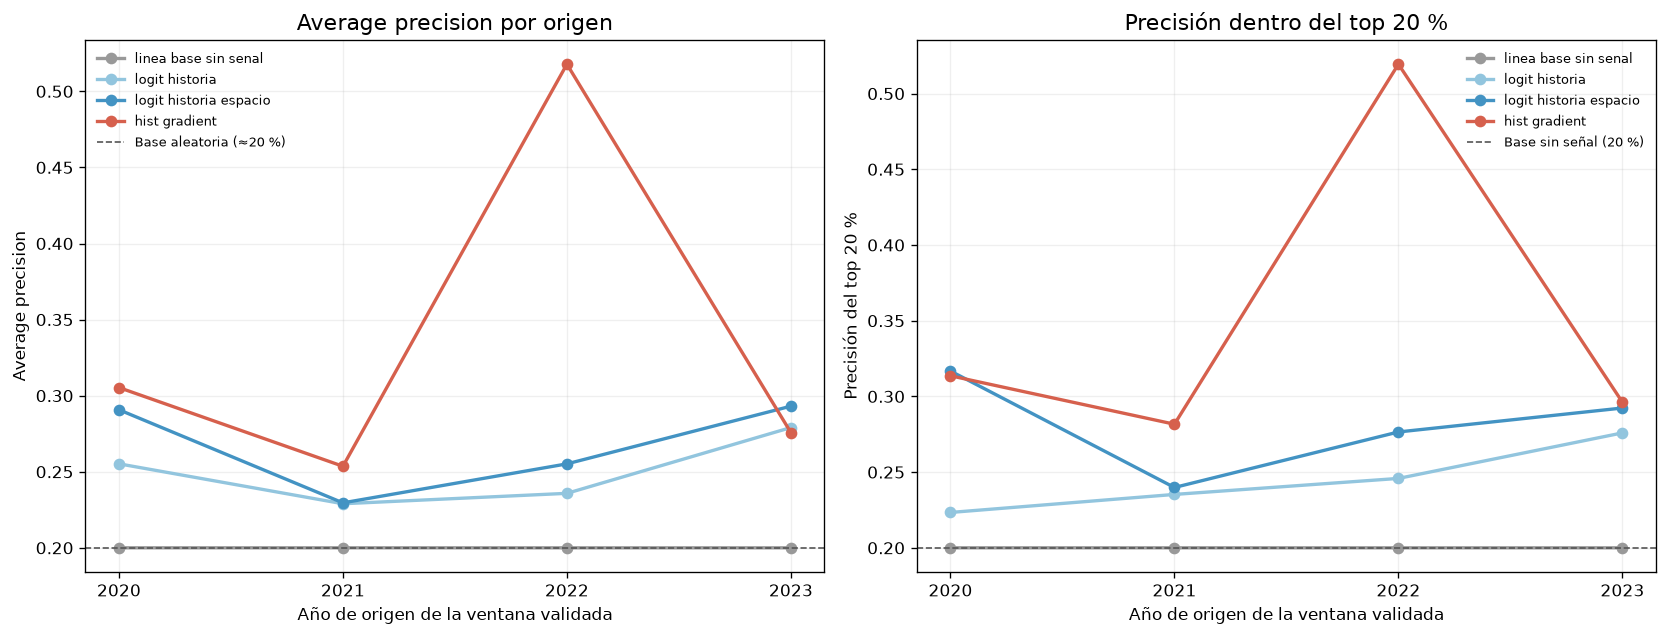

,modelo,origenes,promedio_precision,auc_roc,precision_top_fraccion,lift_top_fraccion,brier
0,hist_gradient,4,0.338,0.648,35.3%,1.76×,0.158
1,logit_historia_espacio,4,0.267,0.579,28.1%,1.41×,0.159
2,logit_historia,4,0.250,0.567,24.5%,1.23×,0.159
3,linea_base_sin_senal,4,0.200,0.500,20.0%,1.00×,0.160


In [9]:
metricas_display = metricas[["origen_validacion", "modelo", "n", "promedio_precision", "auc_roc", "precision_top_fraccion", "lift_top_fraccion"]].copy()
display(metricas_display.sort_values(["origen_validacion", "modelo"]).style.format({
    "promedio_precision": "{:.3f}", "auc_roc": "{:.3f}",
    "precision_top_fraccion": "{:.1%}", "lift_top_fraccion": "{:.2f}×", "n": "{:,.0f}"
}))

modelos_graf = ["linea_base_sin_senal", "logit_historia", "logit_historia_espacio", "hist_gradient"]
colores = ["#999999", "#92c5de", "#4393c3", "#d6604d"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, variable, titulo, ylabel in [
    (axes[0], "promedio_precision", "Average precision por origen", "Average precision"),
    (axes[1], "precision_top_fraccion", "Precisión dentro del top 20 %", "Precisión del top 20 %"),
]:
    pivot = metricas.pivot(index="origen_validacion", columns="modelo", values=variable)
    for modelo, color in zip(modelos_graf, colores):
        if modelo in pivot:
            ax.plot(pivot.index, pivot[modelo], marker="o", linewidth=2, label=modelo.replace("_", " "), color=color)
    if variable == "promedio_precision":
        ax.axhline(.20, color="#555555", linestyle="--", linewidth=1, label="Base aleatoria (≈20 %)")
    else:
        ax.axhline(.20, color="#555555", linestyle="--", linewidth=1, label="Base sin señal (20 %)")
    ax.set_title(titulo)
    ax.set_xlabel("Año de origen de la ventana validada")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(metricas.origen_validacion.unique()))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

display(resumen_modelos.sort_values("promedio_precision", ascending=False).style.format({
    "promedio_precision": "{:.3f}", "auc_roc": "{:.3f}",
    "precision_top_fraccion": "{:.1%}", "lift_top_fraccion": "{:.2f}×", "brier": "{:.3f}"
}))

### Lectura del desempeño

El modelo seleccionado por el promedio de `average precision` es `HistGradientBoosting`. En la validación más reciente (origen 2023, ventana 2023–2026), el top 20 % del ranking contiene **29,6 %** de las manzanas etiquetadas históricamente como oportunidades altas: **1,48 veces** la proporción de la línea base. La `average precision` reciente es 0,276 frente a 0,200 para la línea base.

En las predicciones fuera de tiempo agregadas, el lift del top es **1,74×** (intervalo bootstrap por sector 95 %: **1,64–1,85**). El intervalo describe variación entre sectores remuestreados y no recoge por completo la variación entre periodos. El origen 2022 presenta un resultado mucho mayor que los otros cortes, así que conviene ponderar más la evidencia reciente y no leer el promedio como garantía de desempeño futuro.

## 6. Variables asociadas con la clasificación

La importancia se estimó por permutación en el origen de validación más reciente. La caída de `average precision` al desordenar una variable indica cuánto dependía la métrica de esa señal en esa validación. Es una medida predictiva, no causalidad.

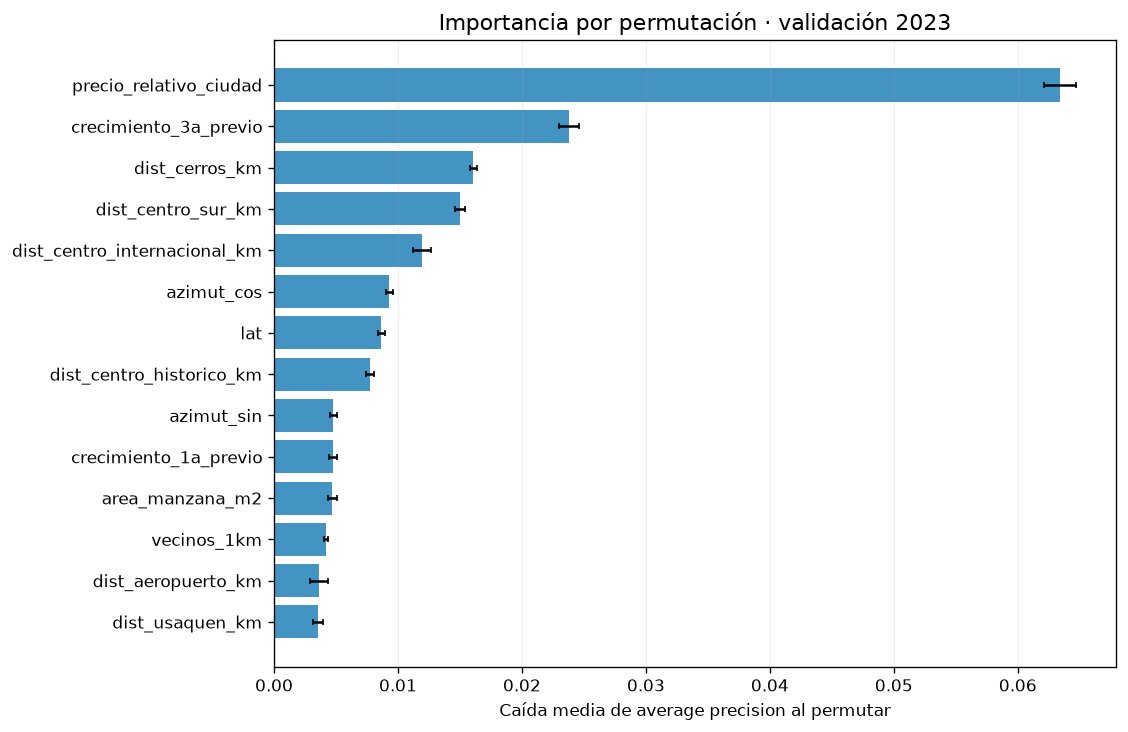

,variable,caida_promedio_precision,desvio
0,precio_relativo_ciudad,0.0634,0.0013
1,crecimiento_3a_previo,0.0238,0.0008
2,dist_cerros_km,0.0161,0.0003
3,dist_centro_sur_km,0.0150,0.0004
4,dist_centro_internacional_km,0.0119,0.0007
5,azimut_cos,0.0093,0.0003
6,lat,0.0087,0.0003
7,dist_centro_historico_km,0.0077,0.0003
8,azimut_sin,0.0048,0.0003
9,crecimiento_1a_previo,0.0047,0.0003


In [10]:
top_importancia = importancia.sort_values("caida_promedio_precision", ascending=False).head(14).sort_values("caida_promedio_precision")
fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.barh(top_importancia.variable, top_importancia.caida_promedio_precision, color="#4393c3", xerr=top_importancia.desvio, capsize=2)
ax.set_title(f"Importancia por permutación · validación {ultimo_origen}")
ax.set_xlabel("Caída media de average precision al permutar")
ax.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()
display(importancia.head(12).style.format({"caida_promedio_precision": "{:.4f}", "desvio": "{:.4f}"}))

**Interpretación:** el precio relativo de partida es la señal más influyente; también contribuyen el crecimiento previo y la ubicación. La presencia de ubicación entre las variables importantes describe asociaciones espaciales del patrón histórico. No implica que una distancia o localización cause por sí misma la valorización.

## 7. Ranking experimental 2026–2029

El puntaje de 0 a 100 expresa la posición relativa entre las manzanas puntuadas. No está calibrado como probabilidad. Se muestran las primeras 20 y la distribución espacial del grupo priorizado del 20 %.

,Puesto,Manzana,Sector,Avalúo inicial COP/m²,Puntaje relativo,Contexto valor / intensidad,Filtro contextual
0,1,008533069,008533,"59,000",100.00,nan,False
1,2,002599075,002599,"573,376",100.00,31.0,False
2,3,008104050,008104,"360,000",100.00,nan,False
3,4,009229058,009229,"3,060,000",99.99,36.1,False
4,5,008521021,008521,"256,000",99.99,nan,False
5,6,008107024,008107,"360,000",99.99,nan,False
6,7,008540020,008540,"108,000",99.99,nan,False
7,8,004530088,004530,"292,000",99.98,nan,False
8,9,008107005,008107,"360,000",99.98,nan,False
9,10,009229064,009229,"3,060,000",99.98,49.5,False


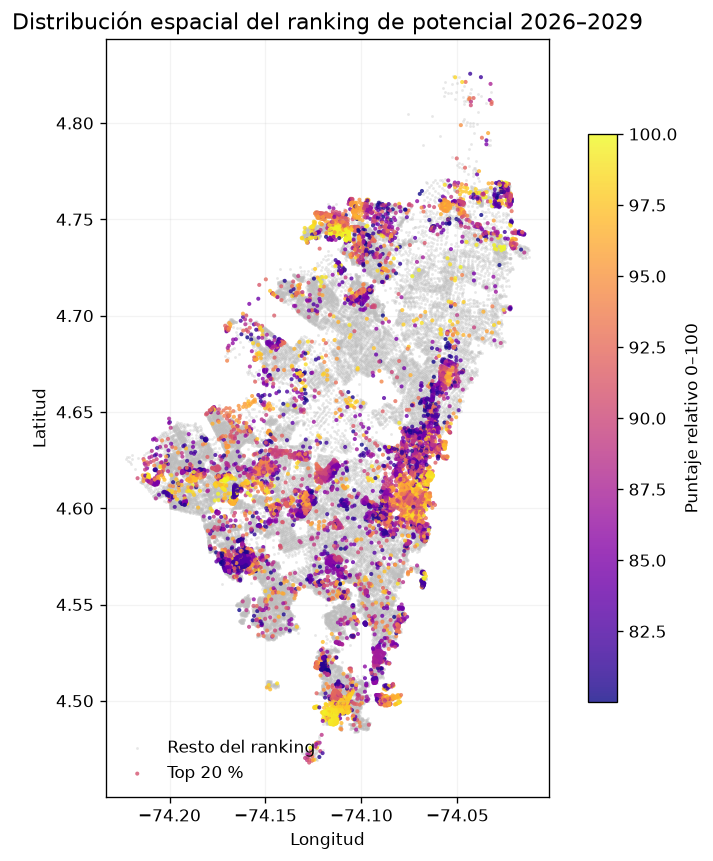

Manzanas del ranking con geometría disponible: 41,570 de 41,823.


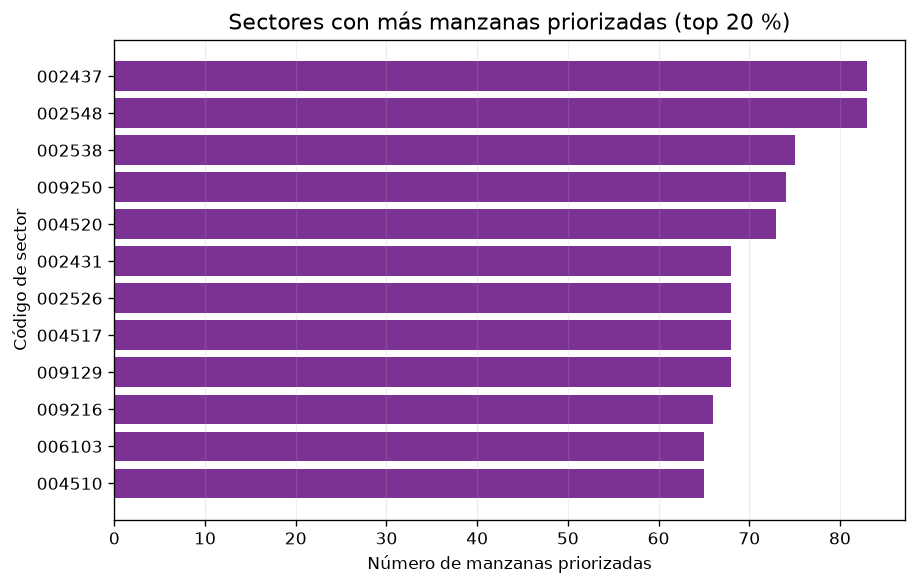

In [11]:
top20 = ranking.sort_values("puesto_ranking").head(20).merge(
    contexto[["MANCODIGO", "score_contextual_0_100", "valor_alto_baja_intensidad"]],
    on="MANCODIGO", how="left")
tabla_top20 = top20[["puesto_ranking", "MANCODIGO", "sector", "cop_m2_inicio", "score_potencial_0_100", "score_contextual_0_100", "valor_alto_baja_intensidad"]].rename(columns={
    "puesto_ranking": "Puesto", "MANCODIGO": "Manzana", "sector": "Sector",
    "cop_m2_inicio": "Avalúo inicial COP/m²", "score_potencial_0_100": "Puntaje relativo",
    "score_contextual_0_100": "Contexto valor / intensidad", "valor_alto_baja_intensidad": "Filtro contextual"
})
display(tabla_top20.style.format({"Avalúo inicial COP/m²": "{:,.0f}", "Puntaje relativo": "{:.2f}", "Contexto valor / intensidad": "{:.1f}"}))

geo = manzanas[["MANCODIGO", "lon", "lat"]].merge(
    ranking[["MANCODIGO", "score_potencial_0_100", "candidato_top_fraccion"]],
    on="MANCODIGO", how="inner").dropna(subset=["lon", "lat"])
fig, ax = plt.subplots(figsize=(8.4, 8.2))
resto = geo[~geo.candidato_top_fraccion]
priorizadas = geo[geo.candidato_top_fraccion]
ax.scatter(resto.lon, resto.lat, s=3, color="#bdbdbd", alpha=.35, linewidths=0, label="Resto del ranking")
sc = ax.scatter(priorizadas.lon, priorizadas.lat, c=priorizadas.score_potencial_0_100,
                s=6, cmap="plasma", alpha=.8, linewidths=0, label="Top 20 %")
ax.set_aspect(1 / np.cos(np.deg2rad(geo.lat.median())))
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Distribución espacial del ranking de potencial 2026–2029")
ax.legend(frameon=False, loc="lower left")
fig.colorbar(sc, ax=ax, label="Puntaje relativo 0–100", shrink=.75)
ax.grid(alpha=.15)
plt.show()
con_geometria = int(ranking.MANCODIGO.isin(manzanas.MANCODIGO).sum())
print(f"Manzanas del ranking con geometría disponible: {con_geometria:,} de {len(ranking):,}.")

top_sectores = (ranking[ranking.candidato_top_fraccion]
                .groupby("sector").size().sort_values(ascending=False).head(12)
                .sort_values())
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(top_sectores.index.astype(str), top_sectores.values, color="#7b3294")
ax.set_title("Sectores con más manzanas priorizadas (top 20 %)")
ax.set_xlabel("Número de manzanas priorizadas")
ax.set_ylabel("Código de sector")
ax.grid(axis="x", alpha=.2)
plt.show()

## 8. Contexto edificatorio: alto avalúo y baja intensidad

El indicador complementario combina percentil alto de avalúo 2026 por m² con percentiles bajos de índice de construcción, ocupación y pisos. La bandera selecciona el cuartil superior del precio y el cuartil inferior de intensidad conjunta. Es un **filtro de revisión urbana**, no una conclusión de edificabilidad ni un segundo modelo de valorización.

,Resumen,Valor
0,Manzanas con contexto calculado,39378.000000
1,Precio 2026 en percentil ≥75,10277.000000
2,Intensidad edificatoria en percentil ≤25,7102.000000
3,Cumplen ambos criterios contextuales,1389.000000
4,Fracción de todas las manzanas,0.033414


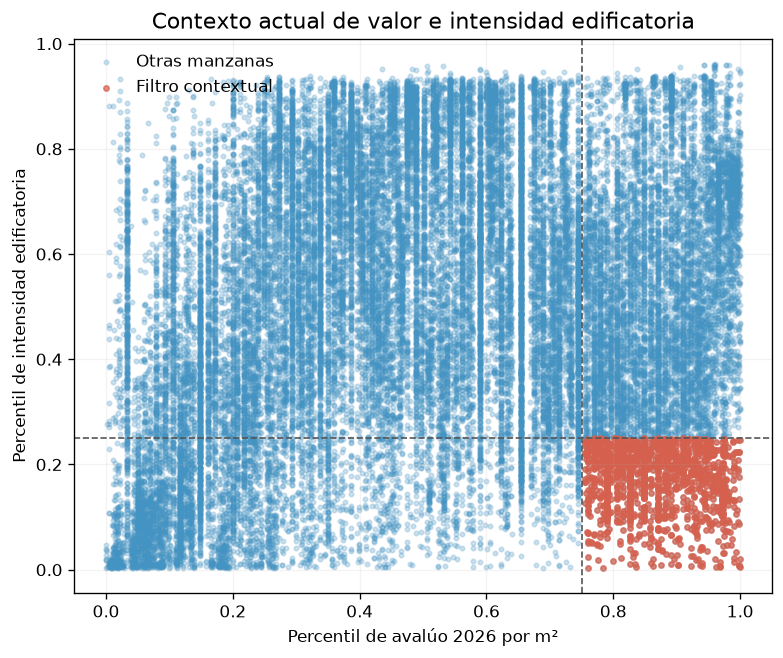

,MANCODIGO,sector,cop_m2_2026,indice_construccion,indice_ocupacion,pisos_prom_pond,score_contextual_0_100
0,006216010,006216,"13,000,000",0.003660,0.003660,1.000000,99.7
1,008410008,008410,"12,500,000",0.015097,0.015097,1.000000,99.6
2,003107010,003107,"11,705,000",0.026458,0.026458,1.000000,99.5
3,003107022,003107,"17,426,000",0.143819,0.143819,1.000000,99.0
4,008303036,008303,"8,450,000",0.082256,0.082256,1.000000,98.9
5,006303018,006303,"8,424,000",0.174678,0.174678,1.000000,98.4
6,009124058,009124,"5,535,000",0.004727,0.004727,1.000000,98.2
7,003109012,003109,"5,494,000",0.019217,0.019217,1.000000,98.1
8,008313021,008313,"8,611,000",0.253050,0.253050,1.000000,98.0
9,005110052,005110,"5,318,000",0.007174,0.007174,1.000000,97.8


In [12]:
flag = contexto.valor_alto_baja_intensidad.fillna(False)
resumen_contexto = pd.DataFrame([
    ("Manzanas con contexto calculado", int(contexto.score_contextual_0_100.notna().sum())),
    ("Precio 2026 en percentil ≥75", int((contexto.valor_m2_percentil >= .75).sum())),
    ("Intensidad edificatoria en percentil ≤25", int((contexto.intensidad_edificatoria_percentil <= .25).sum())),
    ("Cumplen ambos criterios contextuales", int(flag.sum())),
    ("Fracción de todas las manzanas", flag.mean()),
], columns=["Resumen", "Valor"])
display(resumen_contexto)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(contexto.valor_m2_percentil, contexto.intensidad_edificatoria_percentil,
           s=7, alpha=.25, color="#4393c3", label="Otras manzanas")
ax.scatter(contexto.loc[flag, "valor_m2_percentil"], contexto.loc[flag, "intensidad_edificatoria_percentil"],
           s=10, alpha=.7, color="#d6604d", label="Filtro contextual")
ax.axvline(.75, color="#555555", linestyle="--", linewidth=1)
ax.axhline(.25, color="#555555", linestyle="--", linewidth=1)
ax.set_xlabel("Percentil de avalúo 2026 por m²")
ax.set_ylabel("Percentil de intensidad edificatoria")
ax.set_title("Contexto actual de valor e intensidad edificatoria")
ax.legend(frameon=False)
ax.grid(alpha=.15)
plt.show()

display(contexto.loc[flag].sort_values("score_contextual_0_100", ascending=False).head(15)[
    ["MANCODIGO", "sector", "cop_m2_2026", "indice_construccion", "indice_ocupacion", "pisos_prom_pond", "score_contextual_0_100"]
].style.format({"cop_m2_2026": "{:,.0f}", "score_contextual_0_100": "{:.1f}"}))

## 9. Análisis integrado y recomendaciones

### Qué sugieren los datos

- Hay cobertura suficiente para comparar miles de manzanas por año, pero el número cubierto varía y las series no son perfectamente balanceadas.
- El valor de referencia nominal aumenta durante el periodo observado. Para hablar de valorización real habría que deflactar y aclarar el uso de avalúo administrativo frente a transacciones.
- El modelo mejora la priorización frente a una selección sin señal en el backtest, especialmente en la validación más reciente; la mejora es moderada y el rendimiento varía por origen.
- El precio relativo inicial, el crecimiento histórico y la ubicación aportan la mayor señal predictiva en la última validación.
- El indicador morfológico ayuda a detectar manzanas con valor actual alto e intensidad construida baja para inspección, pero no determina la viabilidad del desarrollo.

### Límites para tomar decisiones

1. **No hay verdad futura aún:** el periodo 2026–2029 no cuenta con avalúos observados que permitan medir el acierto del ranking.
2. **Avalúo no es transacción:** la variable objetivo es la valorización catastral relativa, no un precio de venta ni retorno financiero.
3. **No se ajustó por inflación:** las cifras anuales presentadas son nominales.
4. **Variación temporal:** la validación de origen 2022 es atípicamente fuerte. El intervalo bootstrap por sectores no reemplaza más cortes temporales.
5. **Morfología actual:** faltan snapshots históricos consistentes para evaluar cambios de edificaciones sin fuga temporal.
6. **Escala de manzana:** las restricciones y el potencial legal dependen de predios y normas del POT, no disponibles en este modelo.

### Siguiente iteración recomendada

Deflactar la serie con IPC; incorporar transacciones comparables si están disponibles; obtener históricos de licencias/construcción y parámetros POT por predio; y mantener validación temporal cuando se publiquen avalúos futuros. Después, medir estabilidad del top por sector y traducir el ranking a un flujo de inspección, no a una probabilidad de rentabilidad.

In [13]:
conclusiones = pd.DataFrame([
    ("Unidad y horizonte", f"Manzana · {config['anio_corte']}–{config['anio_fin_objetivo']}"),
    ("Etiqueta histórica", "Top 20 % de crecimiento anual residual frente al esperado por precio inicial"),
    ("Modelo", modelo_elegido),
    ("Backtest reciente", f"AP {ultimo.promedio_precision:.3f}; top 20 % {ultimo.precision_top_fraccion:.1%}; lift {ultimo.lift_top_fraccion:.2f}×"),
    ("Lift OOF sectorial", f"{ci['lift_media']:.2f}× (IC 95 % {ci['lift_ic95_inferior']:.2f}–{ci['lift_ic95_superior']:.2f})"),
    ("Lectura del ranking", "Priorización exploratoria, puntaje relativo sin calibración probabilística"),
], columns=["Conclusión", "Resultado"])
display(conclusiones)
print("Fuentes de resultados: potencial_manzanas/outputs/ y data/ del proyecto original.")

,Conclusión,Resultado
0,Unidad y horizonte,Manzana · 2026–2029
1,Etiqueta histórica,Top 20 % de crecimiento anual residual frente ...
2,Modelo,hist_gradient
3,Backtest reciente,AP 0.276; top 20 % 29.6%; lift 1.48×
4,Lift OOF sectorial,1.74× (IC 95 % 1.64–1.85)
5,Lectura del ranking,"Priorización exploratoria, puntaje relativo si..."


Fuentes de resultados: potencial_manzanas/outputs/ y data/ del proyecto original.
